# 03 — Exploratory Data Analysis

## Project: Traffic & Accident Risk Analytics

### Objective

Explore Texas crash records for Dallas and Tarrant counties from 2021 through 2025 to understand crash patterns, severity, environmental conditions, and data quality.

### Research focus

- Understand the distribution of crash severity.
- Explore monthly, yearly, and seasonal crash patterns.
- Examine weather, lighting, and road conditions.
- Identify class imbalance and missing data.
- Establish a foundation for trustworthy AI and reliable prediction.

### Data sources

Texas CRIS public crash extracts for Dallas and Tarrant counties.

### Data quality note

The 2023 dataset was reconstructed from two date ranges: January–March and April–December. The combined crash file contains 92,082 records across all 12 months. We will validate the data before analysis.

### Scope limitation

These records describe reported crashes. This dataset alone cannot estimate the probability of a crash occurring at a location and time where no crash was recorded. Predictive analysis will focus on crash severity among recorded crashes.

## Step 1: Connect to the project

In [3]:
from pathlib import Path
import subprocess

REPO_URL = (
    "https://github.com/rishitha-2602/"
    "traffic-accident-risk-analytics.git"
)

possible_paths = [
    Path("/content/traffic-accident-risk-analytics"),
    Path("/content/traffic-accident-risk-analytics-colab"),
]

PROJECT_ROOT = next(
    (
        path for path in possible_paths
        if (path / ".git").exists()
    ),
    None
)

if PROJECT_ROOT is None:
    PROJECT_ROOT = Path("/content/traffic-accident-risk-analytics-colab")

    if not PROJECT_ROOT.exists():
        subprocess.run(
            ["git", "clone", REPO_URL, str(PROJECT_ROOT)],
            check=True
        )
    elif not (PROJECT_ROOT / ".git").exists():
        raise RuntimeError(
            f"{PROJECT_ROOT} exists but is not a Git repository. "
            "Do not delete it. Please share the folder listing."
        )

DATA_DIR = PROJECT_ROOT / "data" / "raw"
REPORT_DIR = PROJECT_ROOT / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)
print("Data directory exists:", DATA_DIR.exists())
print("Reports directory:", REPORT_DIR)

Project: /content/traffic-accident-risk-analytics
Data directory: /content/traffic-accident-risk-analytics/data/raw
Data directory exists: True
Reports directory: /content/traffic-accident-risk-analytics/reports


## Step 2 — Verify Annual Crash Files

In [4]:
missing_files = []

for year in range(2021, 2026):
    crash_file = DATA_DIR / str(year) / "crash.csv"

    if crash_file.exists():
        print(f"{year}: Found crash.csv")
    else:
        print(f"{year}: MISSING crash.csv")
        missing_files.append(year)

if missing_files:
    print("\nMissing years:", missing_files)
    print(
        "Stop here. Colab may not have the latest files "
        "or the repository may not contain the raw datasets."
    )
else:
    print("\nAll five annual crash files are available.")

2021: Found crash.csv
2022: Found crash.csv
2023: Found crash.csv
2024: Found crash.csv
2025: Found crash.csv

All five annual crash files are available.


## Step 3 — Load Annual Crash Datasets

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

crash_data = {}

for year in range(2021, 2026):
    file_path = DATA_DIR / str(year) / "crash.csv"

    df = pd.read_csv(file_path, low_memory=False)
    df["Source_Year"] = year
    crash_data[year] = df

    print(
        f"{year}: {len(df):,} rows, "
        f"{len(df.columns):,} columns"
    )

crashes = pd.concat(
    crash_data.values(),
    ignore_index=True,
    sort=False
)

print("\nCombined dataset shape:", crashes.shape)
display(crashes.head())

2021: 97,947 rows, 175 columns
2022: 94,700 rows, 175 columns
2023: 92,082 rows, 184 columns
2024: 83,092 rows, 184 columns
2025: 82,670 rows, 184 columns

Combined dataset shape: (450491, 184)


,Crash_ID,Crash_Fatal_Fl,Cmv_Involv_Fl,Schl_Bus_Fl,Rr_Relat_Fl,Medical_Advisory_Fl,Amend_Supp_Fl,Active_School_Zone_Fl,Crash_Date,Crash_Time,...,Source_Year,Secondary_Crash_Fl,Rpt_Dir_Traffic,Rpt_Sec_Speed_Limit,Investigat_Time_Rwy_Clrd,Investigat_Time_Scn_Clrd,Investigat_Notify_Date,Investigat_Arrv_Date,Investigat_Date_Rwy_Clrd,Investigat_Date_Scn_Clrd
0,13808771,N,N,N,N,N,Y,N,04/21/2021,04:50 PM,...,2021,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,17013970,N,N,N,N,N,Y,N,07/16/2021,09:56 AM,...,2021,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,17785987,N,N,N,N,N,Y,N,07/25/2021,08:46 AM,...,2021,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,18038241,N,N,N,N,N,N,N,01/01/2021,03:48 AM,...,2021,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,18038267,N,N,N,N,N,N,N,01/01/2021,03:19 AM,...,2021,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Step 4 — Inspect Dataset Structure

In [6]:
print("Combined dataset dimensions:", crashes.shape)

print("\nColumn names:")
for column in crashes.columns:
    print(column)

print("\nData types:")
display(
    crashes.dtypes.astype(str)
    .value_counts()
    .rename_axis("Data_Type")
    .to_frame("Column_Count")
)

print("\nFirst five records:")
display(crashes.head())

Combined dataset dimensions: (450491, 184)

Column names:
Crash_ID
Crash_Fatal_Fl
Cmv_Involv_Fl
Schl_Bus_Fl
Rr_Relat_Fl
Medical_Advisory_Fl
Amend_Supp_Fl
Active_School_Zone_Fl
Crash_Date
Crash_Time
Case_ID
Local_Use
Rpt_CRIS_Cnty_ID
Rpt_City_ID
Rpt_Outside_City_Limit_Fl
Thousand_Damage_Fl
Rpt_Latitude
Rpt_Longitude
Rpt_Rdwy_Sys_ID
Rpt_Hwy_Num
Rpt_Hwy_Sfx
Rpt_Road_Part_ID
Rpt_Block_Num
Rpt_Street_Pfx
Rpt_Street_Name
Rpt_Street_Sfx
Private_Dr_Fl
Toll_Road_Fl
Crash_Speed_Limit
Road_Constr_Zone_Fl
Road_Constr_Zone_Wrkr_Fl
Rpt_Street_Desc
At_Intrsct_Fl
Rpt_Sec_Rdwy_Sys_ID
Rpt_Sec_Hwy_Num
Rpt_Sec_Hwy_Sfx
Rpt_Sec_Road_Part_ID
Rpt_Sec_Block_Num
Rpt_Sec_Street_Pfx
Rpt_Sec_Street_Name
Rpt_Sec_Street_Sfx
Rpt_Ref_Mark_Offset_Amt
Rpt_Ref_Mark_Dist_Uom
Rpt_Ref_Mark_Dir
Rpt_Ref_Mark_Nbr
Rpt_Sec_Street_Desc
Rpt_CrossingNumber
Wthr_Cond_ID
Light_Cond_ID
Entr_Road_ID
Road_Type_ID
Road_Algn_ID
Surf_Cond_ID
Traffic_Cntl_ID
Investigat_Notify_Time
Investigat_Notify_Meth
Investigat_Arrv_Time
Report_Date
Inve

,Column_Count
Data_Type,
float64,83
object,63
int64,38



First five records:


,Crash_ID,Crash_Fatal_Fl,Cmv_Involv_Fl,Schl_Bus_Fl,Rr_Relat_Fl,Medical_Advisory_Fl,Amend_Supp_Fl,Active_School_Zone_Fl,Crash_Date,Crash_Time,...,Source_Year,Secondary_Crash_Fl,Rpt_Dir_Traffic,Rpt_Sec_Speed_Limit,Investigat_Time_Rwy_Clrd,Investigat_Time_Scn_Clrd,Investigat_Notify_Date,Investigat_Arrv_Date,Investigat_Date_Rwy_Clrd,Investigat_Date_Scn_Clrd
0,13808771,N,N,N,N,N,Y,N,04/21/2021,04:50 PM,...,2021,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,17013970,N,N,N,N,N,Y,N,07/16/2021,09:56 AM,...,2021,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,17785987,N,N,N,N,N,Y,N,07/25/2021,08:46 AM,...,2021,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,18038241,N,N,N,N,N,N,N,01/01/2021,03:48 AM,...,2021,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,18038267,N,N,N,N,N,N,N,01/01/2021,03:19 AM,...,2021,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Step 5 — Identify Important Variables

In [7]:
keywords = [
    "Crash_ID",
    "Crash_Date",
    "Crash_Time",
    "Crash_Sev_ID",
    "Crash_Fatal_Fl",
    "Weather",
    "Light",
    "Surface",
    "Speed",
    "Latitude",
    "Longitude",
    "Cnty",
    "City",
    "Intersection",
]

for keyword in keywords:
    matches = [
        col for col in crashes.columns
        if keyword.lower() in col.lower()
    ]
    print(f"{keyword}: {matches[:15]}")

Crash_ID: ['Crash_ID']
Crash_Date: ['Crash_Date']
Crash_Time: ['Crash_Time']
Crash_Sev_ID: ['Crash_Sev_ID']
Crash_Fatal_Fl: ['Crash_Fatal_Fl']
Weather: []
Light: ['Light_Cond_ID']
Surface: []
Speed: ['Crash_Speed_Limit', 'Rpt_Sec_Speed_Limit']
Latitude: ['Rpt_Latitude', 'Latitude']
Longitude: ['Rpt_Longitude', 'Longitude']
Cnty: ['Rpt_CRIS_Cnty_ID', 'Cnty_ID']
City: ['Rpt_City_ID', 'Rpt_Outside_City_Limit_Fl', 'City_ID']
Intersection: []


## Step 6 — Validate Date Coverage

In [8]:
date_col = next(
    (c for c in crashes.columns if c.lower() == "crash_date"),
    None
)

if date_col is None:
    raise KeyError("Could not find a Crash_Date column.")

crashes["Crash_Date_Parsed"] = pd.to_datetime(
    crashes[date_col],
    errors="coerce",
    format="mixed"
)

coverage_rows = []

for year in range(2021, 2026):
    year_df = crashes[crashes["Source_Year"] == year]
    dates = year_df["Crash_Date_Parsed"].dropna()

    coverage_rows.append({
        "Year": year,
        "Records": len(year_df),
        "Earliest_Date": dates.min(),
        "Latest_Date": dates.max(),
        "Months_Represented": dates.dt.to_period("M").nunique(),
        "Invalid_Dates": year_df["Crash_Date_Parsed"].isna().sum(),
    })

coverage_df = pd.DataFrame(coverage_rows)
display(coverage_df)

coverage_df.to_csv(
    REPORT_DIR / "eda_date_coverage.csv",
    index=False
)

,Year,Records,Earliest_Date,Latest_Date,Months_Represented,Invalid_Dates
0,2021,97947,2021-01-01,2021-12-31,12,0
1,2022,94700,2022-01-01,2022-12-31,12,0
2,2023,92082,2023-01-01,2023-12-31,12,0
3,2024,83092,2024-01-01,2024-12-31,12,0
4,2025,82670,2025-01-01,2025-12-31,12,0


## Step 7 — Assess Data Quality

In [9]:
quality_rows = []

for year, df in crash_data.items():
    id_col = next(
        (c for c in df.columns if c.lower() == "crash_id"),
        None
    )

    quality_rows.append({
        "Year": year,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Exact_Duplicate_Rows": int(df.duplicated().sum()),
        "Missing_Cells": int(df.isna().sum().sum()),
        "Missing_Crash_IDs": (
            int(df[id_col].isna().sum()) if id_col else None
        ),
        "Unique_Crash_IDs": (
            int(df[id_col].nunique()) if id_col else None
        ),
        "Duplicate_Crash_IDs": (
            int(df[id_col].duplicated().sum()) if id_col else None
        ),
    })

quality_df = pd.DataFrame(quality_rows)
display(quality_df)

quality_df.to_csv(
    REPORT_DIR / "eda_data_quality.csv",
    index=False
)

,Year,Rows,Columns,Exact_Duplicate_Rows,Missing_Cells,Missing_Crash_IDs,Unique_Crash_IDs,Duplicate_Crash_IDs
0,2021,97947,175,0,7375942,0,97947,0
1,2022,94700,175,0,7180877,0,94700,0
2,2023,92082,184,0,7152179,0,92082,0
3,2024,83092,184,0,6224793,0,83092,0
4,2025,82670,184,0,6194748,0,82670,0


## Step 8 — Explore Crash Severity

,Crash_Count,Percentage
Crash_Sev_ID,,
0,30180,6.70
1,12322,2.74
2,62226,13.81
3,69741,15.48
4,2565,0.57
5,273456,60.70
95,1,0.00


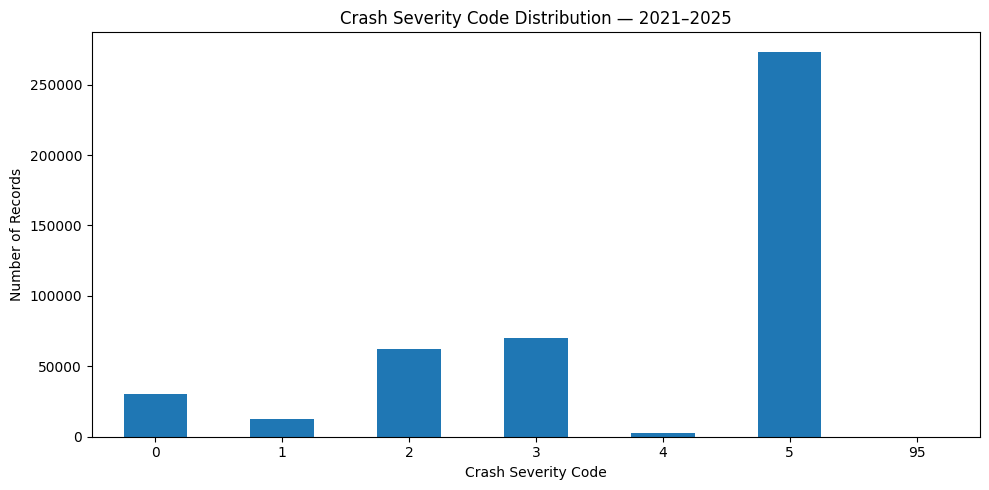

In [10]:
severity_col = next(
    (c for c in crashes.columns if c.lower() == "crash_sev_id"),
    None
)

if severity_col is None:
    print("Crash severity column not found.")
else:
    severity_counts = (
        crashes[severity_col]
        .fillna("Missing")
        .astype(str)
        .value_counts()
        .sort_index()
    )

    severity_summary = pd.DataFrame({
        "Crash_Count": severity_counts,
        "Percentage": (
            severity_counts / severity_counts.sum() * 100
        ).round(2),
    })

    display(severity_summary)

    severity_counts.plot(
        kind="bar",
        figsize=(10, 5)
    )
    plt.title("Crash Severity Code Distribution — 2021–2025")
    plt.xlabel("Crash Severity Code")
    plt.ylabel("Number of Records")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

    severity_summary.to_csv(
        REPORT_DIR / "eda_severity_distribution.csv"
    )

## Step 9 — Explore Monthly Crash Patterns

Source_Year,2021,2022,2023,2024,2025
Crash_Month,,,,,
1,7552,7576,7564,6791,6054
2,6189,7136,6712,6961,5796
3,7907,8113,7888,7129,7001
4,8332,8138,7730,6959,7054
5,8975,8419,7966,7444,7292
6,8499,7775,7435,6320,6465
7,8277,7423,7246,6177,6633
8,8726,7659,7798,6858,7174
9,8260,8146,7751,6900,7100


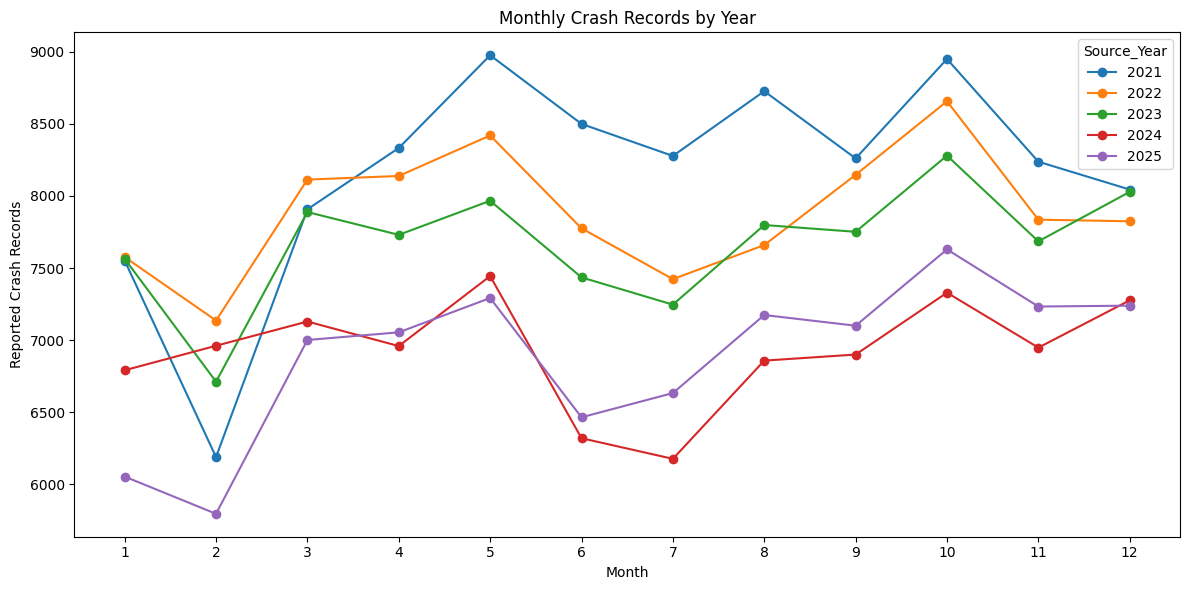

In [11]:
crashes["Crash_Month"] = (
    crashes["Crash_Date_Parsed"].dt.month
)

id_col = next(
    (c for c in crashes.columns if c.lower() == "crash_id"),
    None
)

if id_col is None:
    raise KeyError("Could not find a Crash_ID column.")

monthly_counts = crashes.pivot_table(
    index="Crash_Month",
    columns="Source_Year",
    values=id_col,
    aggfunc="count"
).reindex(range(1, 13))

display(monthly_counts)

monthly_counts.plot(
    figsize=(12, 6),
    marker="o"
)
plt.title("Monthly Crash Records by Year")
plt.xlabel("Month")
plt.ylabel("Reported Crash Records")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

monthly_counts.to_csv(
    REPORT_DIR / "eda_monthly_crash_counts.csv"
)

## Step 10 — Explore Day-of-Week Patterns

,Crash_Count
Day_Of_Week,
Monday,62494
Tuesday,62361
Wednesday,64435
Thursday,64359
Friday,72649
Saturday,66494
Sunday,57699


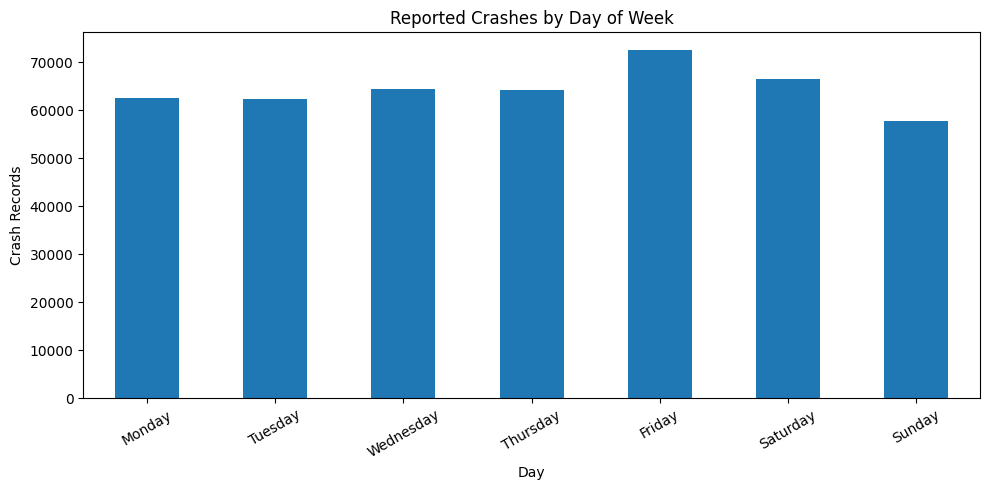

In [12]:
crashes["Day_Of_Week"] = (
    crashes["Crash_Date_Parsed"].dt.day_name()
)

day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

day_counts = (
    crashes["Day_Of_Week"]
    .value_counts()
    .reindex(day_order)
)

display(day_counts.to_frame("Crash_Count"))

day_counts.plot(
    kind="bar",
    figsize=(10, 5)
)
plt.title("Reported Crashes by Day of Week")
plt.xlabel("Day")
plt.ylabel("Crash Records")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

day_counts.to_csv(
    REPORT_DIR / "eda_day_of_week_counts.csv"
)

## Step 11 — Explore Weather and Lighting Conditions

In [13]:
for keyword in ["Weather", "Light"]:
    matching_cols = [
        col for col in crashes.columns
        if keyword.lower() in col.lower()
    ]

    print(f"\n--- {keyword} columns ---")

    if not matching_cols:
        print("No matching columns found.")
        continue

    for col in matching_cols[:3]:
        print(f"\nColumn: {col}")

        summary = (
            crashes[col]
            .fillna("Missing")
            .astype(str)
            .value_counts()
            .head(15)
        )

        display(summary.to_frame("Crash_Count"))


--- Weather columns ---
No matching columns found.

--- Light columns ---

Column: Light_Cond_ID


,Crash_Count
Light_Cond_ID,
1,284914
4,121422
3,24470
6,5985
5,5823
2,4976
0,2570
8,331


## Step 12 — Explore Geographic Coverage

In [14]:
geo_keywords = ["Latitude", "Longitude", "Cnty", "County", "City"]

geo_cols = [
    col for col in crashes.columns
    if any(k.lower() in col.lower() for k in geo_keywords)
]

print("Geographic columns:", geo_cols)

for col in geo_cols:
    print(f"\n{col}")
    display(
        crashes[col]
        .describe()
        .to_frame("Summary")
    )
    print("Missing:", f"{crashes[col].isna().sum():,}")

Geographic columns: ['Rpt_CRIS_Cnty_ID', 'Rpt_City_ID', 'Rpt_Outside_City_Limit_Fl', 'Rpt_Latitude', 'Rpt_Longitude', 'Cnty_ID', 'City_ID', 'Latitude', 'Longitude']

Rpt_CRIS_Cnty_ID


,Summary
count,450491.000000
mean,117.470638
std,78.711118
min,20.000000
25%,57.000000
50%,57.000000
75%,220.000000
max,249.000000


Missing: 0

Rpt_City_ID


,Summary
count,450491.000000
mean,227.309369
std,871.269678
min,3.000000
25%,107.000000
50%,124.000000
75%,177.000000
max,9999.000000


Missing: 0

Rpt_Outside_City_Limit_Fl


...

Missing: 0

Latitude


,Summary
count,416725.000000
mean,32.789354
std,0.100960
min,32.546356
25%,32.715248
50%,32.786647
75%,32.864223
max,32.993960


Missing: 33,766

Longitude


,Summary
count,416725.000000
mean,-96.969724
std,0.247190
min,-97.549849
25%,-97.175522
50%,-96.900908
75%,-96.781759
max,-96.517223


Missing: 33,766


## Step 13 — Explore Missing Values

In [15]:
missing_report = pd.DataFrame({
    "Missing_Count": crashes.isna().sum(),
    "Missing_Percentage": (
        crashes.isna().mean() * 100
    ).round(2),
})

missing_report = (
    missing_report[missing_report["Missing_Count"] > 0]
    .sort_values("Missing_Percentage", ascending=False)
)

display(missing_report.head(30))

missing_report.to_csv(
    REPORT_DIR / "eda_missing_values.csv"
)

,Missing_Count,Missing_Percentage
Investigat_District_ID,450491,100.0
Street_Nbr_2,450491,100.0
Hwy_Dsgn_Hrt_ID,450491,100.0
Investigat_Area_ID,450491,100.0
RRCo,450491,100.0
WDCode_ID,450491,100.0
Poscrossing_ID,450491,100.0
Standstop,450491,100.0
Yield,450491,100.0
Investigator_Narrative,450491,100.0


## Step 14 — Save Exploratory Data Analysis Outputs

In [16]:
print("Project:", PROJECT_ROOT)
print("Reports directory:", REPORT_DIR)

print("\nEDA report files:")
for file_path in sorted(REPORT_DIR.glob("eda_*.csv")):
    print(file_path.name)

print("\nRecords analyzed:", f"{len(crashes):,}")
print("Years analyzed:", sorted(crashes["Source_Year"].unique()))

print("\nAnnual date coverage:")
display(coverage_df)

print("\nData quality summary:")
display(quality_df)

Project: /content/traffic-accident-risk-analytics
Reports directory: /content/traffic-accident-risk-analytics/reports

EDA report files:
eda_data_quality.csv
eda_date_coverage.csv
eda_day_of_week_counts.csv
eda_missing_values.csv
eda_monthly_crash_counts.csv
eda_severity_distribution.csv

Records analyzed: 450,491
Years analyzed: [np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]

Annual date coverage:


,Year,Records,Earliest_Date,Latest_Date,Months_Represented,Invalid_Dates
0,2021,97947,2021-01-01,2021-12-31,12,0
1,2022,94700,2022-01-01,2022-12-31,12,0
2,2023,92082,2023-01-01,2023-12-31,12,0
3,2024,83092,2024-01-01,2024-12-31,12,0
4,2025,82670,2025-01-01,2025-12-31,12,0



Data quality summary:


,Year,Rows,Columns,Exact_Duplicate_Rows,Missing_Cells,Missing_Crash_IDs,Unique_Crash_IDs,Duplicate_Crash_IDs
0,2021,97947,175,0,7375942,0,97947,0
1,2022,94700,175,0,7180877,0,94700,0
2,2023,92082,184,0,7152179,0,92082,0
3,2024,83092,184,0,6224793,0,83092,0
4,2025,82670,184,0,6194748,0,82670,0
